### Lab 7 Python Physics Engine Prototype
**Student:** Zaki Daouk  
**Date:** 2026-10-18

Before running the notebook, install the engine and path helper in the Python environment used by its kernel. From the `phys311` project root, run `python -m pip install -e .\labs\lab07` in the VS Code terminal.

### Part A — Build the Core Engine

The engine is split into modules in `lab07_engine/`: `Body` stores object state, force objects accumulate forces, an `Integrator` advances state, and `World` coordinates fixed timesteps and records snapshots.

Each `World.step(dt)` clears each body's force and torque accumulators, applies every registered force, advances the state, and records a snapshot. `World.run(steps, dt)` repeats that process with the same timestep.

#### Class diagram

```text
+--------------------+      owns       +--------------------+
|       World        |---------------->|       Body         |
| bodies, forces     |                 | m, r, v, force     |
| integrator, time   |                 | theta, omega       |
| history            |                 +--------------------+
+---------+----------+                            ^
          |                                       | adds force
          v                                       |
+--------------------+                   +--------+---------+
|    Integrator      |                   |       Force      |
| step(world, dt)    |                   | apply(world)     |
+---------+----------+                   +---+----------+---+
          | updates                          |          |
          v                                  v          v
+--------------------+                 +----------+ +----------+
|   EulerCromer      |                 | Gravity  | |  Drag    |
+--------------------+                 +----------+ +----------+

World records StateRecord snapshots of positions, kinetic and potential
energy, and linear momentum for plotting and conservation checks.
```

#### Small Engine Example

This projectile registers two force types. Drag is included to demonstrate combining forces; remove the `Drag` registration for an ideal projectile.

In [3]:
from project_paths import add_to_path, project_root

ENGINE_DIR = add_to_path(
    "lab07_engine",
    subdirs=("", "src", "labs/lab07", "lab07", "phys311/labs/lab07"),
)

from lab07_engine import Body, Drag, EulerCromer, Gravity, World  # noqa: E402 (path setup above)

ROOT = project_root(start=ENGINE_DIR)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

dt = 0.01
dt = 0.01
world = World(EulerCromer())
projectile = Body(mass=1.0, pos=[0.0, 0.0], vel=[15.0, 20.0])
world.add_body(projectile)
world.add_force(Gravity())
world.add_force(Drag(c=0.002))

world.run(steps=1000, dt=dt)
initial = world.history[0]
final = world.history[-1]

print(f"Recorded states: {len(world.history)}")
print(f"Final time: {final.time:.2f} s")
print(f"Final position: {final.positions[0]}")
print(f"Initial total energy: {initial.total_energy:.3f} J")
print(f"Final total energy: {final.total_energy:.3f} J")
print(f"Final momentum: {final.momentum} kg·m/s")

Recorded states: 1001
Final time: 10.00 s
Final position: (119.25368643099107, -244.90242891731342)
Initial total energy: 312.500 J
Final total energy: -788.145 J
Final momentum: (7.842061065892905, -56.27786177378487) kg·m/s


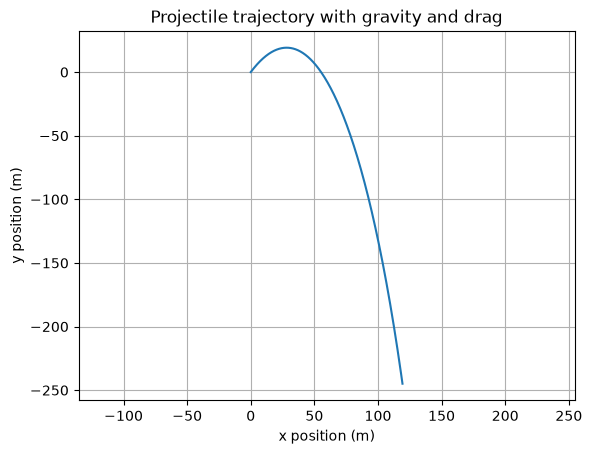

In [4]:
import matplotlib.pyplot as plt
import numpy as np

positions = np.asarray([state.positions[0] for state in world.history])
plt.plot(positions[:, 0], positions[:, 1])
plt.xlabel("x position (m)")
plt.ylabel("y position (m)")
plt.title("Projectile trajectory with gravity and drag")
plt.grid(True)
plt.axis("equal")
plt.savefig(FIG_DIR / "lab07_engine_projectile.png", dpi=160, bbox_inches="tight")
plt.show()